# Tratamento das bases de dados
Pipeline completo de pré-processamento, tratamento de dados extraídos do INMET e seleção de atributos. 


# Importação de Bibliotecas

In [1]:
import re
from pathlib import Path
import pandas as pd
import math
import unicodedata
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Parâmetros

In [2]:
# Coordenadas de referência para a cidade de São Paulo (Marco Zero - Praça da Sé)
LAT_SP = -23.5505
LON_SP = -46.6333

# Coluna target
target_col = 'temperatura_do_ar_bulbo_seco_horaria_c'

estacoes_selecionadas = ["A701", "A771", "A755", "A744", "A706"]


# 1. Carregamento dos dados

In [3]:
def padronizar_colunas(df: pd.DataFrame) -> pd.DataFrame:
    """Padroniza nomes de colunas: minúsculas, sem acento, sem caracteres especiais."""
    def limpar(col: str) -> str:
        col = col.strip()
        col = unicodedata.normalize("NFKD", col).encode("ascii", "ignore").decode("ascii")
        col = col.lower()
        col = re.sub(r"[^\w\s]", " ", col)          # remove pontuação/unidades
        col = re.sub(r"\s+", "_", col.strip())       # espaços -> underscore
        col = re.sub(r"_+", "_", col).strip("_")
        return col

    df = df.copy()
    df.columns = [limpar(c) for c in df.columns]
    # remove eventual coluna 'unnamed' final gerada pelo ';' no fim de cada linha
    df = df.loc[:, ~df.columns.str.contains("^unnamed")]
    return df

    # Função de Haversine para calcular distância
def calcular_distancia(lat1, lon1, lat2, lon2):
    R = 6371.0  # Raio médio da Terra em km
    
    # Conversão de graus para radianos
    lat1, lon1, lat2, lon2 = map(math.radians, [lat1, lon1, lat2, lon2])
    
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    
    a = math.sin(dlat/2)**2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon/2)**2
    c = 2 * math.asin(math.sqrt(a))
    
    return R * c


In [4]:
input_folder = Path("./Inputs")

estacoes = {}
ranking_dados = [] # Lista auxiliar para criar a tabela final

for arquivo in sorted(input_folder.glob("*.csv")):
    with open(arquivo, "r", encoding="utf-8") as f:
        linhas_meta = [f.readline().strip() for _ in range(8)]

    metadata = dict(linha.split(":", 1) for linha in linhas_meta if ":" in linha)
    metadata = {k.strip(): v.strip() for k, v in metadata.items()}

    nome_estacao = metadata["Nome"]
    codigo_estacao = metadata["Codigo Estacao"]
    
    # Captura Lat/Lon e garante que estão no formato numérico (tratando possível vírgula)
    lat_estacao = float(metadata.get("Latitude", "0").replace(",", "."))
    lon_estacao = float(metadata.get("Longitude", "0").replace(",", "."))
    
    # Calcula a distância em km até São Paulo
    distancia_sp = calcular_distancia(LAT_SP, LON_SP, lat_estacao, lon_estacao)
    
    print(f"Carregando estação {codigo_estacao} - {nome_estacao} do arquivo {arquivo.name}")

    df = pd.read_csv(
        arquivo,
        sep=";",
        decimal=",",
        skiprows=9,
        encoding="utf-8",
        na_values=["", " ", "-9999", "null", "NULL"],
    )
    
    df_padronizado = padronizar_colunas(df)
    
    estacoes[codigo_estacao] = {
        "nome": nome_estacao,
        "codigo_estacao": codigo_estacao,
        "dataframe": df_padronizado,
        "distancia_sp_km": distancia_sp,
    }

print(f"\n{len(estacoes)} estações carregadas: {list(estacoes.keys())}\n")


Carregando estação A701 - SAO PAULO - MIRANTE do arquivo dados_A701_H_2020-01-01_2026-01-01.csv
Carregando estação A705 - BAURU do arquivo dados_A705_H_2020-01-01_2026-01-01.csv
Carregando estação A706 - CAMPOS DO JORDAO do arquivo dados_A706_H_2020-01-01_2026-01-01.csv
Carregando estação A707 - PRESIDENTE PRUDENTE do arquivo dados_A707_H_2020-01-01_2026-01-01.csv
Carregando estação A708 - FRANCA do arquivo dados_A708_H_2020-01-01_2026-01-01.csv
Carregando estação A711 - SAO CARLOS do arquivo dados_A711_H_2020-01-01_2026-01-01.csv
Carregando estação A712 - IGUAPE do arquivo dados_A712_H_2020-01-01_2026-01-01.csv
Carregando estação A713 - IPERO do arquivo dados_A713_H_2020-01-01_2026-01-01.csv
Carregando estação A714 - ITAPEVA do arquivo dados_A714_H_2020-01-01_2026-01-01.csv
Carregando estação A715 - SAO MIGUEL ARCANJO do arquivo dados_A715_H_2020-01-01_2026-01-01.csv
Carregando estação A716 - OURINHOS do arquivo dados_A716_H_2020-01-01_2026-01-01.csv
Carregando estação A718 - RANCHARI

# 2. Tratamento dos dados

## 2.1 Dados de data e hora

In [5]:
def combinar_data_hora(df: pd.DataFrame) -> pd.DataFrame:
    """Combina colunas de data e hora do INMET em um DatetimeIndex único."""
    df = df.copy()

    # hora vem no formato HHMM (ex.: '0000', '1300') -> normaliza para 'HH:MM'
    hora_str = df["hora_medicao"].astype(str).str.zfill(4)
    hora_fmt = hora_str.str[:2] + ":" + hora_str.str[2:]

    df["timestamp"] = pd.to_datetime(
        df["data_medicao"].astype(str) + " " + hora_fmt,
        format="%Y-%m-%d %H:%M",
        errors="coerce",
    )

    n_invalidos = df["timestamp"].isna().sum()
    print(f"Timestamps inválidos/não convertidos: {n_invalidos}")

    df = df.dropna(subset=["timestamp"])
    df = df.drop(columns=["data_medicao", "hora_medicao"])
    df = df.set_index("timestamp")
    return df

def criar_features_temporais(df: pd.DataFrame) -> pd.DataFrame:
    """Cria features de calendário e codificações cíclicas (seno/cosseno)."""
    df = df.copy()

    df["hora"] = df.index.hour
    df["dia"] = df.index.day
    df["mes"] = df.index.month
    df["ano"] = df.index.year
    # df["dia_semana"] = df.index.dayofweek          # 0 = segunda, 6 = domingo
    # df["is_fim_de_semana"] = (df["dia_semana"] >= 5).astype(int)
    df["dia_ano"] = df.index.dayofyear

    # Codificação cíclica - ciclo diário (24h)
    df["hora_sin"] = np.sin(2 * np.pi * df["hora"] / 24)
    df["hora_cos"] = np.cos(2 * np.pi * df["hora"] / 24)

    # Codificação cíclica - ciclo anual (~365.25 dias)
    df["dia_ano_sin"] = np.sin(2 * np.pi * df["dia_ano"] / 365.25)
    df["dia_ano_cos"] = np.cos(2 * np.pi * df["dia_ano"] / 365.25)

    return df#.loc[df.index.year<2026]



In [6]:
for codigo, estacao in estacoes.items():
    df = estacao["dataframe"]
    df = combinar_data_hora(df)
    df = criar_features_temporais(df)
    estacoes[codigo]["dataframe"] = df
    print(f"Estação {codigo} - {estacao['nome']}: shape final {df.shape}")

Timestamps inválidos/não convertidos: 0
Estação A701 - SAO PAULO - MIRANTE: shape final (52632, 29)
Timestamps inválidos/não convertidos: 0
Estação A705 - BAURU: shape final (52632, 29)
Timestamps inválidos/não convertidos: 0
Estação A706 - CAMPOS DO JORDAO: shape final (52632, 29)
Timestamps inválidos/não convertidos: 0
Estação A707 - PRESIDENTE PRUDENTE: shape final (52632, 29)
Timestamps inválidos/não convertidos: 0
Estação A708 - FRANCA: shape final (52632, 29)
Timestamps inválidos/não convertidos: 0
Estação A711 - SAO CARLOS: shape final (52632, 29)
Timestamps inválidos/não convertidos: 0
Estação A712 - IGUAPE: shape final (52632, 29)
Timestamps inválidos/não convertidos: 0
Estação A713 - IPERO: shape final (52632, 29)
Timestamps inválidos/não convertidos: 0
Estação A714 - ITAPEVA: shape final (52632, 29)
Timestamps inválidos/não convertidos: 0
Estação A715 - SAO MIGUEL ARCANJO: shape final (52632, 29)
Timestamps inválidos/não convertidos: 0
Estação A716 - OURINHOS: shape final (5

In [7]:
# estacoes["A701"]["nome"]
estacoes["A701"]["dataframe"].head()

,precipitacao_total_horario_mm,pressao_atmosferica_ao_nivel_da_estacao_horaria_mb,pressao_atmosferica_reduzida_nivel_do_mar_aut_mb,pressao_atmosferica_max_na_hora_ant_aut_mb,pressao_atmosferica_min_na_hora_ant_aut_mb,radiacao_global_kj_m2,temperatura_da_cpu_da_estacao_c,temperatura_do_ar_bulbo_seco_horaria_c,temperatura_do_ponto_de_orvalho_c,temperatura_maxima_na_hora_ant_aut_c,...,vento_velocidade_horaria_m_s,hora,dia,mes,ano,dia_ano,hora_sin,hora_cos,dia_ano_sin,dia_ano_cos
timestamp,,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:00:00,0.0,922.3,1009.9,922.3,921.2,-3.5,26.0,23.3,18.1,24.1,...,1.8,0,1,1,2020,1,0.000000,1.000000,0.017202,0.999852
2020-01-01 01:00:00,0.0,922.7,1010.5,922.7,922.3,-3.5,25.0,23.0,18.1,23.4,...,0.9,1,1,1,2020,1,0.258819,0.965926,0.017202,0.999852
2020-01-01 02:00:00,0.0,922.4,1010.1,922.7,922.4,-3.5,25.0,23.1,17.8,23.2,...,1.0,2,1,1,2020,1,0.500000,0.866025,0.017202,0.999852
2020-01-01 03:00:00,0.0,921.9,1009.6,922.4,921.9,-3.5,24.0,23.0,17.5,23.1,...,0.2,3,1,1,2020,1,0.707107,0.707107,0.017202,0.999852
2020-01-01 04:00:00,0.0,921.4,1009.2,921.9,921.4,-3.5,24.0,22.3,17.5,23.0,...,0.5,4,1,1,2020,1,0.866025,0.500000,0.017202,0.999852


## 2.2 Avaliação de nulos

In [8]:
def tabela_nulos(df: pd.DataFrame) -> pd.DataFrame:
    """Retorna tabela com quantidade e percentual de nulos por coluna, ordenada decrescente."""
    n_nulos = df.isna().sum()
    pct_nulos = (n_nulos / len(df) * 100).round(2)
    tabela = pd.DataFrame({"n_nulos": n_nulos, "pct_nulos": pct_nulos})
    tabela = tabela[tabela["n_nulos"] > 0].sort_values("pct_nulos", ascending=False)
    return tabela


### a) Plot 

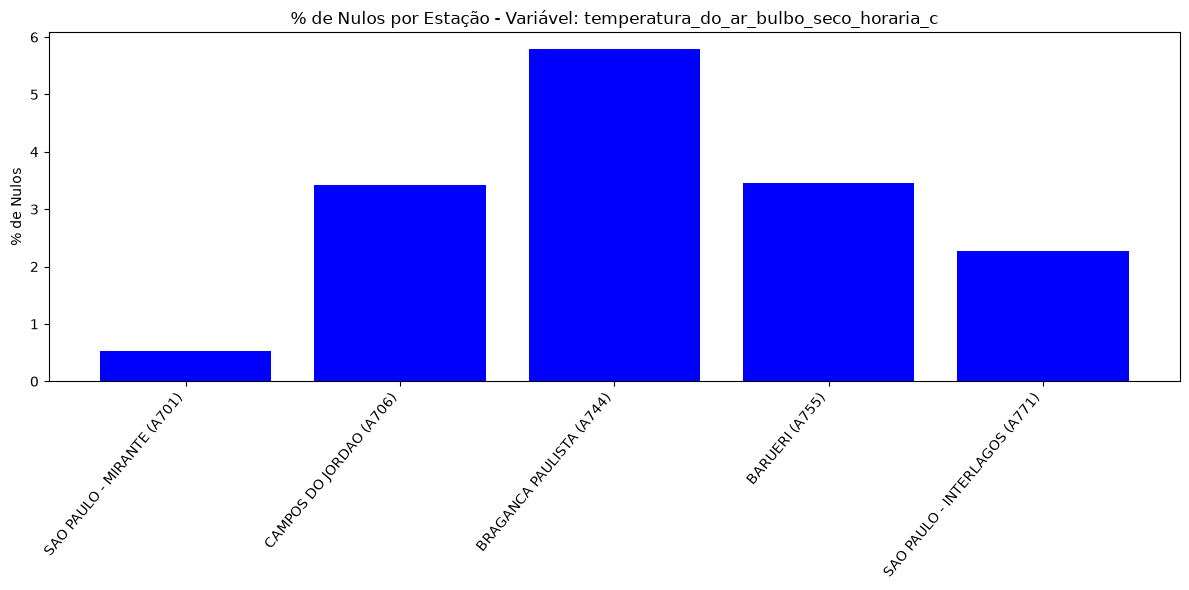

In [9]:
nomes_estacoes = []
pcts_nulos = []

for codigo, estacao in estacoes.items():
    if codigo in estacoes_selecionadas:
        df = estacao["dataframe"]
        
        # Calcula a % de nulos apenas para a target_col nesta estação
        pct = (df[target_col].isnull().sum() / len(df)) * 100
        
        # Guarda os dados para plotar depois
        nomes_estacoes.append(f"{estacao['nome']} ({codigo})")
        pcts_nulos.append(pct)

plt.figure(figsize=(12, 6)) # Aumentar a largura também ajuda
plt.bar(nomes_estacoes, pcts_nulos, color='blue')

plt.title(f"% de Nulos por Estação - Variável: {target_col}")
plt.ylabel("% de Nulos")
# plt.xlabel("Código da Estação")
plt.xticks(rotation=50, ha='right') 

plt.tight_layout()
plt.show()

### b) Ranking

In [10]:
nomes_estacoes = []
pcts_nulos = []
distancias_sp = [] # Nova lista para guardar as distâncias

for codigo, estacao in estacoes.items():
    df = estacao["dataframe"]
    
    # Calcula a % de nulos apenas para a target_col nesta estação
    pct = (df[target_col].isnull().sum() / len(df)) * 100
    
    # Resgata a distância calculada na etapa de carregamento
    distancia = estacao["distancia_sp_km"]
    
    # Guarda os dados nas listas para construir o dataframe depois
    nomes_estacoes.append(f"{estacao['nome']} ({codigo})")
    pcts_nulos.append(pct)
    distancias_sp.append(distancia)

# --- GERANDO O RANKING ---
# Substituímos o XXX por um dicionário que dá nome às colunas
df_ranking = pd.DataFrame({
    "Estação": nomes_estacoes,
    "% Nulos": pcts_nulos,
    "Distância SP (km)": distancias_sp
})

# Ordenamos o DataFrame prioritariamente pela % de nulos (do menor para o maior)
# e, como critério de desempate/secundário, a distância em relação a SP (da menor para a maior)
df_ranking_ordenado = df_ranking.sort_values(by=["% Nulos", "Distância SP (km)"], ascending=[True, True])

# Opcional: Resetar o index para o ranking ficar bonitinho de 0 a N
df_ranking_ordenado = df_ranking_ordenado.reset_index(drop=True)

display(df_ranking_ordenado)

,Estação,% Nulos,Distância SP (km)
0,MARILIA (A763),0.300198,371.284796
1,PRADOPOLIS (A747),0.398997,289.233548
2,SAO PAULO - MIRANTE (A701),0.531996,6.177156
3,SAO SIMAO (A770),1.970284,251.837308
4,SAO PAULO - INTERLAGOS (A771),2.262882,19.858877
5,BAURU (A705),2.302782,278.820681
6,PRESIDENTE PRUDENTE (A707),3.305974,514.536878
7,CAMPOS DO JORDAO (A706),3.421873,137.820153
8,BARUERI (A755),3.456072,24.254590
9,TUPA (A768),4.599863,434.752050


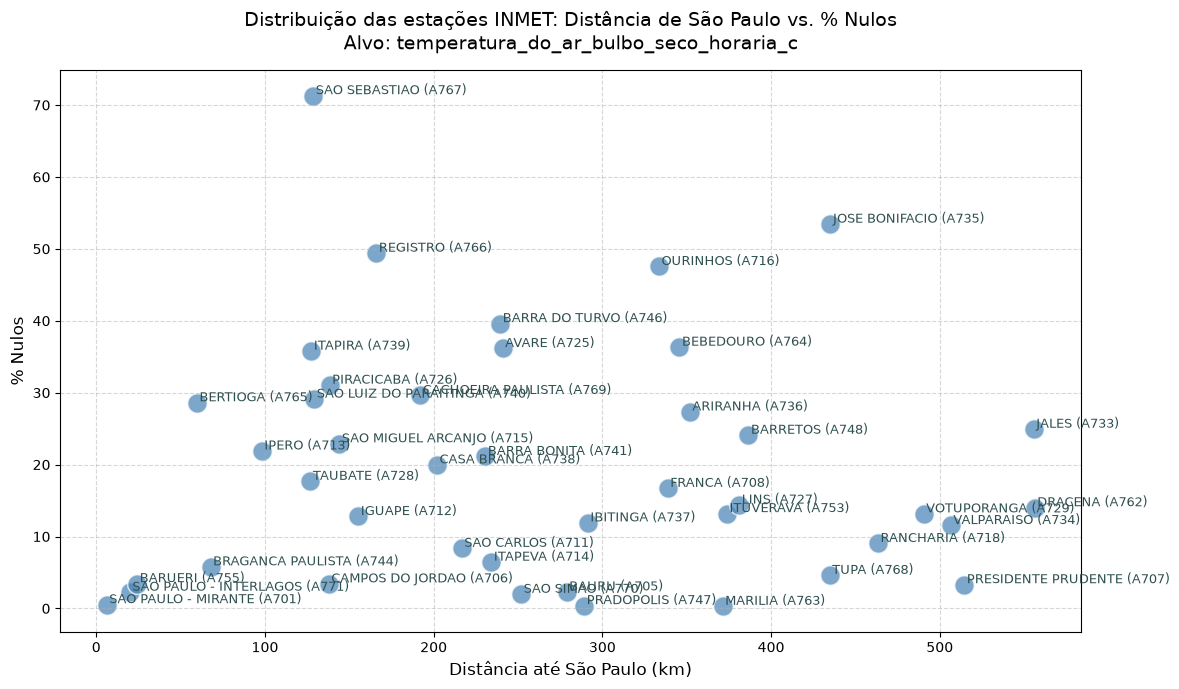

In [11]:
# Define o tamanho da figura
plt.figure(figsize=(12, 7))

# Cria o gráfico de dispersão (bolhas)
# O parâmetro 's' define o tamanho das bolhas e 'alpha' a transparência
sns.scatterplot(
    data=df_ranking_ordenado, 
    x="Distância SP (km)", 
    y="% Nulos",
    s=200, 
    color="steelblue",
    alpha=0.7,
    # edgecolor="black"
)

# Adiciona os nomes das estações ao lado de cada bolha para fácil identificação
for i in range(len(df_ranking_ordenado)):
    # Deslocamos levemente o texto no eixo X (+1.5) e Y (+0.5) para não ficar em cima da bolha
    plt.text(
        x=df_ranking_ordenado["Distância SP (km)"].iloc[i] + 1.5, 
        y=df_ranking_ordenado["% Nulos"].iloc[i] + 0.2, 
        s=df_ranking_ordenado["Estação"].iloc[i],
        fontsize=9,
        color="darkslategray"
    )

# Adiciona títulos e rótulos
plt.title(f"Distribuição das estações INMET: Distância de São Paulo vs. % Nulos\nAlvo: {target_col}", fontsize=14, pad=15)
plt.xlabel("Distância até São Paulo (km)", fontsize=12)
plt.ylabel("% Nulos", fontsize=12)

# Adiciona uma grade de fundo para facilitar a leitura dos eixos
plt.grid(True, linestyle='--', alpha=0.5)

# Ajusta o layout e exibe o gráfico
plt.tight_layout()
plt.show()

## 2.3 Avaliação de outliers

In [12]:
# Definindo os limites físicos do domínio climático
limite_superior = 40.0
limite_inferior = -5.0

print(f"--- Verificação de Limites Físicos (Alvo: {target_col}) ---\n")

for codigo, estacao in estacoes.items():
    if codigo in estacoes_selecionadas: # Assumindo que você manteve a lista das selecionadas
        df = estacao["dataframe"] # É importante validar no dado original, antes de qualquer tratamento
        
        # Cria as máscaras booleanas e soma as ocorrências (True = 1)
        qtd_acima = (df[target_col] > limite_superior).sum()
        qtd_abaixo = (df[target_col] < limite_inferior).sum()
        
        total_absurdos = qtd_acima + qtd_abaixo
        
        print(f"Estação {codigo} ({estacao['nome']}):")
        print(f"  - Registros > {limite_superior}°C: {qtd_acima}")
        print(f"  - Registros < {limite_inferior}°C: {qtd_abaixo}")
        
        if total_absurdos > 0:
            print(f"  ⚠️ ATENÇÃO: {total_absurdos} valores anômalos detectados!")
        print("-" * 45)

--- Verificação de Limites Físicos (Alvo: temperatura_do_ar_bulbo_seco_horaria_c) ---

Estação A701 (SAO PAULO - MIRANTE):
  - Registros > 40.0°C: 0
  - Registros < -5.0°C: 0
---------------------------------------------
Estação A706 (CAMPOS DO JORDAO):
  - Registros > 40.0°C: 0
  - Registros < -5.0°C: 0
---------------------------------------------
Estação A744 (BRAGANCA PAULISTA):
  - Registros > 40.0°C: 0
  - Registros < -5.0°C: 0
---------------------------------------------
Estação A755 (BARUERI):
  - Registros > 40.0°C: 0
  - Registros < -5.0°C: 0
---------------------------------------------
Estação A771 (SAO PAULO - INTERLAGOS):
  - Registros > 40.0°C: 0
  - Registros < -5.0°C: 0
---------------------------------------------


## 2.4 Tratamento dos nulos

### a) Plot Nulos

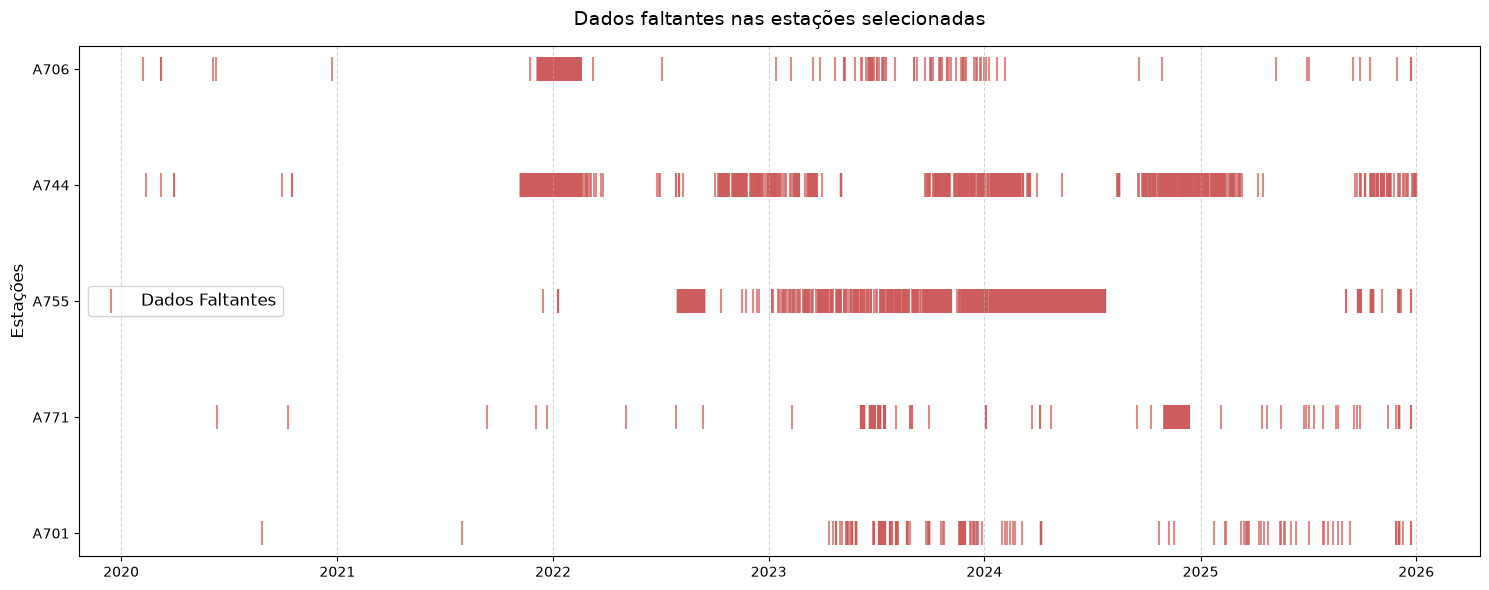

In [13]:
# estacoes_selecionadas_old = ["A701", "A771", "A755", "A744", "A706", "A711", "A714", "A705", "A770", "A747"]
plt.figure(figsize=(15, 6))

for eixo_y, codigo in enumerate(estacoes_selecionadas):
    # Pegamos o dataframe original (cru) para ver a real situação dos sensores
    df = estacoes[codigo]["dataframe"]
    
    # Isola apenas os índices das linhas onde a temperatura é NaN
    linhas_nulas = df[df[target_col].isnull()].index
    
    # Plota os nulos como riscos verticais (|)
    plt.scatter(
        x=linhas_nulas, 
        y=[eixo_y] * len(linhas_nulas), 
        marker='|', 
        color='indianred', 
        s=300, # Tamanho do risco
        alpha=0.7
    )

# Configurações visuais do gráfico
plt.yticks(range(len(estacoes_selecionadas)), estacoes_selecionadas)
plt.title(f"Dados faltantes nas estações selecionadas", fontsize=14, pad=15)
# plt.xlabel("Progressão do Tempo (Índice da Medição Horária)", fontsize=12)
plt.ylabel("Estações", fontsize=12)
plt.legend(["Dados Faltantes"], fontsize=12)
# Adiciona uma grade no eixo X para facilitar a leitura da linha do tempo
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### b) Tratamento

In [14]:
for codigo, estacao in estacoes.items():
    if codigo in estacoes_selecionadas:
        print(f"Tratando nulos da estação {codigo}...")
        
        # Trabalhamos com uma cópia para preservar o dataframe original intacto
        df_interpolado = estacao["dataframe"].copy()
        
        cols_numericas = df_interpolado.select_dtypes(include=['float64', 'int64']).columns
        
        for col in cols_numericas:
            # Passo A: Interpolação para micro-falhas (até 6h)
            df_interpolado[col] = df_interpolado[col].interpolate(method='pchip', limit=6, limit_direction='both')
            
            # Passo B: Calcula a média daquele mês, dia e hora ao longo de todo o histórico da estação
            media_sazonal = df_interpolado.groupby([df_interpolado.index.month, df_interpolado.index.day, df_interpolado.index.hour])[col].transform('mean')
            df_interpolado[col] = df_interpolado[col].fillna(media_sazonal)
            
    
        nulos_antes = estacao["dataframe"][target_col].isnull().sum()
        nulos_depois = df_interpolado[target_col].isnull().sum()
        nulos_resolvidos = nulos_antes - nulos_depois
        
        print(f"Estação {codigo} - {estacao['nome']}:")
        print(f"  - Nulos Originais: {nulos_antes}")
        print(f"  - Nulos Restantes: {nulos_depois} ({nulos_resolvidos} resolvidos)")

        # Salva o resultado em uma nova chave
        estacoes[codigo]["dataframe_interpolado"] = df_interpolado

print("\nInterpolação concluída para as estações selecionadas.")

Tratando nulos da estação A701...
Estação A701 - SAO PAULO - MIRANTE:
  - Nulos Originais: 280
  - Nulos Restantes: 0 (280 resolvidos)
Tratando nulos da estação A706...
Estação A706 - CAMPOS DO JORDAO:
  - Nulos Originais: 1801
  - Nulos Restantes: 0 (1801 resolvidos)
Tratando nulos da estação A744...
Estação A744 - BRAGANCA PAULISTA:
  - Nulos Originais: 3049
  - Nulos Restantes: 0 (3049 resolvidos)
Tratando nulos da estação A755...
Estação A755 - BARUERI:
  - Nulos Originais: 1819
  - Nulos Restantes: 0 (1819 resolvidos)
Tratando nulos da estação A771...
Estação A771 - SAO PAULO - INTERLAGOS:
  - Nulos Originais: 1191
  - Nulos Restantes: 0 (1191 resolvidos)

Interpolação concluída para as estações selecionadas.


### c) Plot dos dados tratados

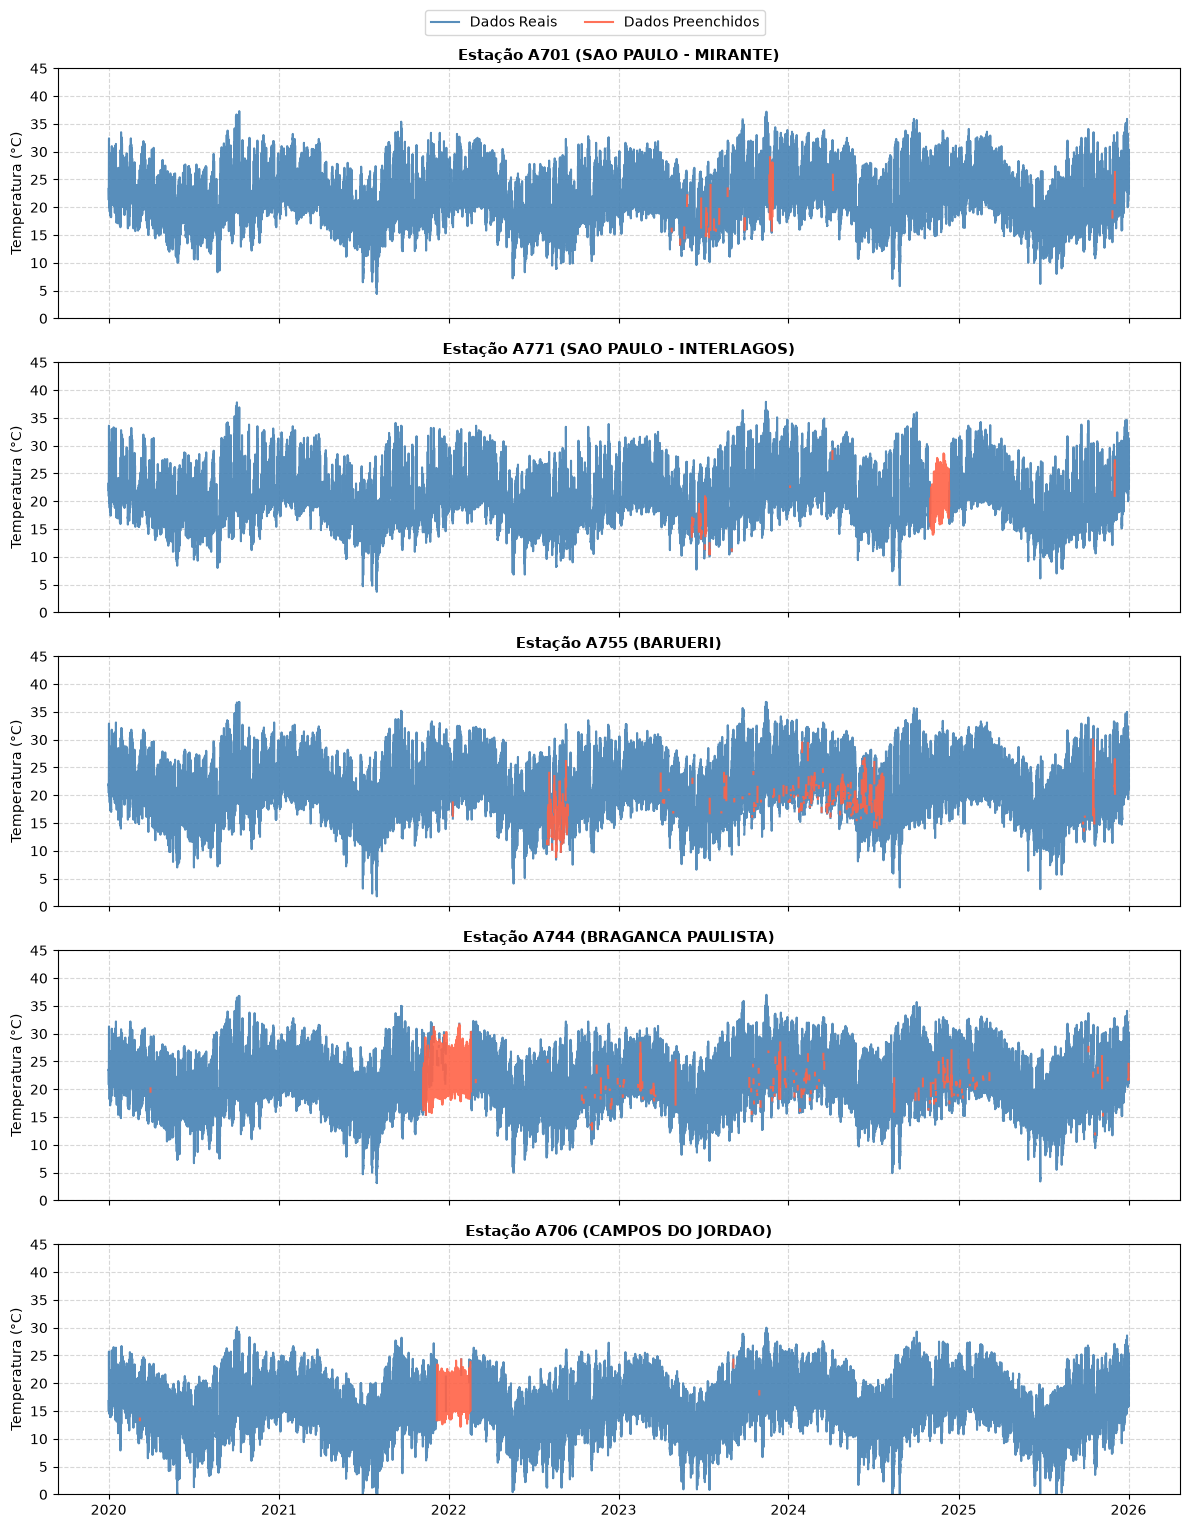

In [15]:
num_estacoes = len(estacoes_selecionadas)

# Cria uma única figura com N subplots empilhados
fig, axes = plt.subplots(num_estacoes, 1, figsize=(12, 3 * num_estacoes), sharex=True)


for ax, codigo in zip(axes, estacoes_selecionadas):
    nome_estacao = estacoes[codigo]['nome']
    
    df_original = estacoes[codigo]["dataframe"]
    df_tratado = estacoes[codigo]["dataframe_interpolado"]

    mascara_nulos = df_original[target_col].isnull()
    
    # Cria a série temporária para os valores imputados
    série_imputada = df_tratado[target_col].copy()
    série_imputada[~mascara_nulos] = np.nan  
    
    # Plota a linha dos dados reais e dos preenchidos no subplot atual
    ax.plot(df_original.index, df_original[target_col], color='steelblue', label='Dados Reais', linewidth=1.5, alpha=0.9)
    ax.plot(df_original.index, série_imputada, color='tomato', label='Dados Preenchidos', linewidth=1.5, alpha=0.9)
    
    ax.set_title(f"Estação {codigo} ({nome_estacao})", fontsize=11, fontweight='bold')
    ax.set_ylabel("Temperatura (°C)", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_ylim(0, 45)

# Adiciona uma única legenda centralizada no topo do gráfico geral
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=2, fontsize=10)

plt.tight_layout()
plt.show()

In [18]:
col = target_col

linhas = []
for codigo, estacao in estacoes.items():
    if codigo not in estacoes_selecionadas:
        continue
    df_interpolado = estacao["dataframe_interpolado"]
    linhas.append({
        "estacao": codigo,
        "media": df_interpolado[col].mean(),
        "maximo": df_interpolado[col].max(),
        "minimo": df_interpolado[col].min(),
    })

df_resumo = pd.DataFrame(linhas)
display(df_resumo)


,estacao,media,maximo,minimo
0,A701,20.625105,37.3,4.4
1,A706,15.123767,30.1,-2.5
2,A744,20.490420,37.0,3.1
3,A755,20.000584,36.8,1.8
4,A771,19.532758,37.9,3.7


# 4. Export final dos dados

In [ ]:
output_folder = Path(r"C:\Users\nasse\OneDrive\Documentos\TCC\Metodologia\dados")

colunas_exportar = [
    target_col, #'temperatura_do_ar_bulbo_seco_horaria_c
    'hora_sin',                                    
    'hora_cos',                                    
    'dia_ano_sin',                                 
    'dia_ano_cos',
    'umidade_relativa_do_ar_horaria',              
    'radiacao_global_kj_m2',                       
    'pressao_atmosferica_reduzida_nivel_do_mar_aut_mb',                                  
]

dfs_finais = []

for codigo in estacoes_selecionadas:
    df_export = estacoes[codigo]["dataframe_interpolado"][colunas_exportar].copy()

    caminho_csv = output_folder / f"{codigo} - {estacoes[codigo]['nome']}.csv"
    df_export.to_csv(caminho_csv, index=True, index_label="timestamp")
    print(f"Estação {codigo} exportada: {caminho_csv} ({df_export.shape[0]} linhas)")

    dfs_finais.append(df_export)

# CSV único (junção de todas as estações selecionadas) para o modelo central
df_geral = pd.concat(dfs_finais, axis=0).sort_index()

caminho_geral = output_folder / "dados_gerais.csv"
df_geral.to_csv(caminho_geral, index=True, index_label="timestamp")
print(f"\nCSV geral exportado: {caminho_geral} ({df_geral.shape[0]} linhas)")


# 5. Avaliação de features

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Colunas que sabemos que são redundantes e devem ser ignoradas na avaliação
colunas_para_ignorar = [
    target_col, 
    'temperatura_maxima_na_hora_ant_aut_c',
    'temperatura_minima_na_hora_ant_aut_c',
    'temperatura_da_cpu_da_estacao_c',
    'temperatura_do_ponto_de_orvalho_c',
    'temperatura_orvalho_max_na_hora_ant_aut_c',
    'temperatura_orvalho_min_na_hora_ant_aut_c'
]

importancias_list = []

for codigo, estacao in estacoes.items():
    if codigo in estacoes_selecionadas:
        df_rf = estacao["dataframe_interpolado"].copy()
        
        # Filtra apenas colunas numéricas
        cols_numericas = df_rf.select_dtypes(include=['float64', 'int64']).columns
        
        # Define os previsores (X) removendo as colunas ignoradas
        features = [col for col in cols_numericas if col not in colunas_para_ignorar]
        
        X = df_rf[features]
        # Preenche qualquer nan residual com a média para o Random Forest não quebrar
        X = X.fillna(X.mean()) 
        y = df_rf[target_col]
        
        # Treina um Random Forest rápido (n_estimators=50 para ser veloz)
        rf_model = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
        rf_model.fit(X, y)
        
        # Extrai a importância (em %)
        importancias = pd.Series(rf_model.feature_importances_, index=features)
        importancias.name = codigo
        
        importancias_list.append(importancias)

# Concatena e calcula a média global
df_importancias = pd.concat(importancias_list, axis=1)
df_importancias['Media_Importancia_Global'] = df_importancias.mean(axis=1)

# Ordena da maior importância para a menor
df_importancias_ordenada = df_importancias.sort_values(by='Media_Importancia_Global', ascending=False)

print(f"--- Importância das Variáveis (Random Forest) ---")
display(df_importancias_ordenada)

# 99. Testes

In [ ]:
path = r"C:\Users\nasse\OneDrive\Documentos\TCC\Metodologia\dados\A701 - SAO PAULO - MIRANTE.csv"
df= pd.read_csv(path, index_col="timestamp", parse_dates=True)

df.iloc[:, 0].mean()         # primeira coluna, por posição



In [ ]:
col_teste = 'radiacao_global_kj_m2'
for codigo in estacoes_selecionadas:
    nome_estacao = estacoes[codigo]['nome']
    
    # Extrai os dataframes
    df_original = estacoes[codigo]["dataframe"]
    df_tratado = estacoes[codigo]["dataframe_interpolado"]
    df_tratado_teste = estacoes[codigo]["dataframe_interpolado_teste"]

    mascara_nulos = df_original[col_teste].isnull()
    
    # Cria uma coluna temporária separada apenas para os valores imputados
    # Tudo que não era nulo vira NaN na série imputada, isolando só o que o algoritmo gerou
    série_imputada = df_tratado[col_teste].copy()
    série_imputada[~mascara_nulos] = np.nan  
    
    # Cria figura com 2 subplots
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
    
    # ===== PRIMEIRO GRÁFICO: Séries sobrepostas =====
    # 1. Plota a linha do dado real (Azul)
    ax1.plot(df_plot.index, df_original[col_teste], color='steelblue', label='Dado Real', linewidth=1)

    ax1.set_title(f"Comparação de Métodos de Imputação - Estação {codigo} ({nome_estacao})", 
                  fontsize=12, fontweight='bold')
    ax1.set_ylabel(col_teste, fontsize=12)
    # ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=9)
    ax1.grid(True, linestyle='--', alpha=0.5)
    ax1.set_ylim(0, 45)
    
# ===== Segundo GRÁFICO: =====   
    # 2. Plota os dados do primeiro método (Vermelho)
    ax2.plot(df_plot.index, df_original[col_teste], color='steelblue', label='Dados Reais', 
                 linewidth=2, alpha=0.9)
    ax2.plot(df_plot.index, série_imputada, color='tomato', label='Dados Preenchido', 
             linewidth=2, alpha=0.9)
    
    ax2.set_title(f"Dados Tratados - Estação {codigo} ({nome_estacao})", fontsize=12, fontweight='bold')
    # ax2.set_ylabel("Temperatura (°C)", fontsize=12)
    ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=9)
    ax2.grid(True, linestyle='--', alpha=0.5)
    ax2.set_ylim(0, 45)    
    
    plt.tight_layout()
    plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

target_col = 'temperatura_do_ar_bulbo_seco_horaria_c'

print("Gerando gráficos de validação por estação...\n")

for codigo in estacoes_selecionadas:
    nome_estacao = estacoes[codigo]['nome']
    
    # Extrai os dataframes
    df_original = estacoes[codigo]["dataframe"]
    df_tratado = estacoes[codigo]["dataframe_interpolado"]
    
    # Cria uma cópia do original para manipularmos a exibição
    df_plot = df_original.copy()
    
    # Identifica exatamente onde eram os nulos no dado original
    mascara_nulos = df_plot[target_col].isnull()
    
    # Cria uma coluna temporária separada apenas para os valores imputados
    # Tudo que não era nulo vira NaN na série imputada, isolando só o que o algoritmo gerou
    série_imputada = df_tratado[target_col].copy()
    série_imputada[~mascara_nulos] = np.nan  
    
    # Na série original, mantemos os dados reais e deixamos os nulos como NaN
    # (o matplotlib automaticamente "quebra" a linha azul onde há buracos)
    
    plt.figure(figsize=(16, 5))
    
    # 1. Plota a linha do dado real (Azul)
    plt.plot(df_plot.index, df_plot[target_col], color='steelblue', label='Dado Real (Original)', linewidth=1)
    
    # 2. Plota por cima, exatamente nos buracos, os dados gerados pelo algoritmo (Vermelho/Laranja)
    # Como usamos marcadores ou uma linha pontilhada grossa, fica evidente onde o algoritmo atuou
    plt.plot(df_plot.index, série_imputada, color='tomato', label='Dado Interpolado', 
             linewidth=2, alpha=0.9)
    
    # Configurações visuais do gráfico
    plt.title(f"Inspeção de Imputação de Falhas - Estação {codigo} ({nome_estacao})", fontsize=14, fontweight='bold')
    plt.ylabel("Temperatura (°C)", fontsize=12)
    plt.xlabel("Linha do Tempo (2020 - 2026)", fontsize=12)
    
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.xticks(rotation=0)
    plt.ylim(0, 45)
    
    plt.tight_layout()
    plt.show()

In [ ]:
import matplotlib.pyplot as plt

target_col = 'temperatura_do_ar_bulbo_seco_horaria_c'

print("Gerando gráficos individuais de série temporal...\n")

for codigo in estacoes_selecionadas:
    # Puxa o dado bruto com o índice de tempo contínuo
    df = estacoes[codigo]["dataframe"]
    
    # Cria uma nova figura dimensionada horizontalmente para cada estação
    plt.figure(figsize=(15, 4))
    
    # Plota a temperatura. O Matplotlib automaticamente corta a linha ao encontrar os NaNs gerados pelo asfreq('h')
    plt.plot(df.index, df[target_col], color='steelblue', linewidth=1)
    
    # Configurações visuais de cada gráfico
    plt.title(f"Série Histórica e Apagões Reais - Estação {codigo}", fontsize=14, fontweight='bold')
    plt.ylabel("Temperatura (°C)", fontsize=12)
    plt.xlabel("Data da Medição", fontsize=12)
    
    # Rotaciona as datas no eixo X em 45 graus para evitar que os textos se sobreponham
    plt.xticks(rotation=45)
    
    # Adiciona uma grade leve para facilitar a leitura
    plt.grid(True, linestyle='--', alpha=0.5)
    
    # Define limites fixos no eixo Y para padronizar a comparação visual entre as estações
    plt.ylim(0, 45) 
    
    # Ajusta as margens e renderiza o gráfico atual antes de ir para a próxima estação do loop
    plt.tight_layout()
    plt.show()